### **Hotel Booking Prediction: Dataset Initialization**
 Reading the dataset into the environment and examining the first five entries.

In [15]:
import pandas as pd

# Load the uploaded dataset
dataset_path = '/content/hotel_bookings.csv'
df_new_uploaded = pd.read_csv(dataset_path)

# Display the top 5 rows
display(df_new_uploaded.head(5))

num_instances, num_features = df_new_uploaded.shape
print(f"Total Instances (Rows): {num_instances}")
print(f"Total Features (Columns): {num_features}")

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Total Instances (Rows): 119390
Total Features (Columns): 32


### **Data Preprocessing** ###
Data is successfully processed, validated, and saved in your active environment:

1. Identify and Handle Missing Values:
Numerical missing values (like children) were imputed with the median.

2. Categorical missing values (like country) were imputed with the constant value 'Unknown'.
3. Identify and Handle Duplicates:
Successfully identified and dropped 31,994 duplicate rows.
4. Identify and Drop Unused Columns:
Removed highly sparse columns (company, agent) and features that lead to data leakage (reservation_status, reservation_status_date).

Apply Encoding:
OneHotEncoder on categorical columns, expanding them into individual numeric binary columns.

Apply Feature Scaling:
Used StandardScaler on numeric values to normalize training variance.


Summary of Preprocessing Completed
All tasks in your checklist have been successfully processed, validated, and saved in your active environment:



In [16]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Identify and handle duplicates
duplicates_count = df_new_uploaded.duplicated().sum()
print(f"Number of duplicate rows found: {duplicates_count}")
df_cleaned = df_new_uploaded.drop_duplicates().copy()
print(f"Shape after removing duplicates: {df_cleaned.shape}")

# 2. Identify missing values
missing_vals = df_cleaned.isnull().sum()
print("Missing values per column:")
print(missing_vals[missing_vals > 0])

# 3. Drop columns that are not useful
# 'company' has a massive amount of missing values, and high cardinality identifiers like 'agent' can be dropped
# 'reservation_status' highly leaks the target 'is_canceled', so it must be dropped
# 'reservation_status_date' can also be dropped to prevent data leakage
cols_to_drop = ['company', 'agent', 'reservation_status', 'reservation_status_date']
cols_to_drop = [col for col in cols_to_drop if col in df_cleaned.columns]
df_cleaned = df_cleaned.drop(columns=cols_to_drop)

# Define target and features
target_col = 'is_canceled'
X = df_cleaned.drop(columns=[target_col])
y = df_cleaned[target_col]

# Define feature types
num_features = X.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"\nNumerical Features ({len(num_features)}): {num_features}")
print(f"Categorical Features ({len(cat_features)}): {cat_features}")

Number of duplicate rows found: 31994
Shape after removing duplicates: (87396, 32)
Missing values per column:
children        4
country       452
agent       12193
company     82137
dtype: int64

Numerical Features (17): ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
Categorical Features (10): ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type']


###**Splitting of Test and Train Data** ###

Train-Test Split (80:20):
The dataset was split into 69,916 training records and 17,480 testing records.

Maintain Class Distribution:
Stratification kept the target classes balanced at ~72.5% non-canceled (0) and ~27.5% canceled (1) in both sets.

Fixed Random Seed:
Utilized a reproducible random seed (42).
Ensure Fitting Only on Training Data:

Constructed pipelines to only use .fit_transform() on X_train and .transform() on X_test, guaranteeing zero data leakage.


In [17]:
# 4. Train-Test Split (80:20) with Stratified Split and Fixed Random Seed
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Training class distribution:\n{y_train.value_counts(normalize=True)}")
print(f"Testing class distribution:\n{y_test.value_counts(normalize=True)}")

Training set shape: (69916, 27)
Testing set shape: (17480, 27)
Training class distribution:
is_canceled
0    0.725099
1    0.274901
Name: proportion, dtype: float64
Testing class distribution:
is_canceled
0    0.725114
1    0.274886
Name: proportion, dtype: float64


In [18]:
# 5. Building Preprocessing Pipelines
# Numerical pipeline: Impute missing values with median, then apply scaling
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical pipeline: Impute missing values with constant, then apply One-Hot Encoding
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine preprocessors
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_features),
    ('cat', cat_pipeline, cat_features)
])

# 6. Fit and transform training data, and transform test data only (preventing leakage)
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Fetch feature names for encoded columns
encoded_cat_features = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_features)
all_features = num_features + list(encoded_cat_features)

print(f"Processed Training Shape: {X_train_processed.shape}")
print(f"Processed Testing Shape: {X_test_processed.shape}")

Processed Training Shape: (69916, 248)
Processed Testing Shape: (17480, 248)


### Step 3: Model Implementation and Evaluation

We will now train five classification models on the preprocessed training set:
1. **Logistic Regression**
2. **Decision Tree Classifier**
3. **K-Nearest Neighbors (KNN)**
4. **Gaussian Naive Bayes**
5. **Random Forest Classifier (Ensemble)**

For each model, we will evaluate performance on the test set using:
- **Accuracy**
- **AUC Score** (Area Under the ROC Curve)
- **Precision**
- **Recall**
- **F1 Score**
- **Matthews Correlation Coefficient (MCC)**

In [19]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, matthews_corrcoef

# Initialize a list to store metrics for each model
results_list = []

def evaluate_and_record_model(model, name, X_tr, y_tr, X_te, y_te):
    print(f"Training {name}...")
    model.fit(X_tr, y_tr)

    # Predict class labels
    y_pred = model.predict(X_te)

    # Predict probabilities for AUC
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_te)[:, 1]
    elif hasattr(model, "decision_function"):
        y_prob = model.decision_function(X_te)
    else:
        y_prob = y_pred

    # Calculate metrics
    acc = accuracy_score(y_te, y_pred)
    auc = roc_auc_score(y_te, y_prob)
    prec = precision_score(y_te, y_pred, zero_division=0)
    rec = recall_score(y_te, y_pred, zero_division=0)
    f1 = f1_score(y_te, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_te, y_pred)

    results_list.append({
        "Model": name,
        "Accuracy": acc,
        "AUC Score": auc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1,
        "MCC Score": mcc
    })
    print(f"{name} completed.")

#### Model Comparison Table ###

All five machine learning models have been trained and evaluated on hotel bookings dataset. Here is the performance summary of each model across all six requested metrics:

**Key Insights & Performance Analysis:**
Best Overall Classifier:

**Random Forest (Ensemble)** outperforms all other models with an Accuracy of 84.02%, an AUC of 0.8989, and an MCC of 0.5792. It maintains the highest precision (75.96%) and has strong predictive stability across both canceled and non-canceled bookings.
Decision Tree vs. Random Forest:

While the single **Decision Tree **achieves a comparable recall of 61.71% to Random Forest (61.23%), it suffers from lower precision (60.34%) and AUC (0.7331). The Random Forest successfully mitigates variance and overfitting, yielding a higher accuracy and F1 Score.

**K-Nearest Neighbors & Logistic Regression:**

Logistic Regression achieves a respectable AUC of 0.8444 and accuracy of 79.47%, though it has a lower recall of 48.35%.
KNN delivers balanced performance across the board with an F1 Score of 0.5983 and Accuracy of 78.63%.
The Naive Bayes Exception:

**Gaussian Naive Bayes** yields a high Recall of 98.65%, but a very low Accuracy of 38.14% and Precision of 30.60%. This indicates that the model is predicting almost every single instance as 'Canceled', leading to an extremely high rate of false positives.

In [20]:
# Initialize models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Gaussian Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

# Train and evaluate each model
for name, model in models.items():
    evaluate_and_record_model(model, name, X_train_processed, y_train, X_test_processed, y_test)

# Create summary table
df_performance = pd.DataFrame(results_list)
display(df_performance)

Training Logistic Regression...
Logistic Regression completed.
Training Decision Tree...
Decision Tree completed.
Training K-Nearest Neighbors...
K-Nearest Neighbors completed.
Training Gaussian Naive Bayes...
Gaussian Naive Bayes completed.
Training Random Forest...
Random Forest completed.


,Model,Accuracy,AUC Score,Precision,Recall,F1 Score,MCC Score
0,Logistic Regression,0.794680,0.844386,0.677259,0.483455,0.564177,0.445307
1,Decision Tree,0.783238,0.733107,0.603378,0.617066,0.610145,0.460114
2,K-Nearest Neighbors,0.786327,0.815177,0.619048,0.578980,0.598344,0.453485
3,Gaussian Naive Bayes,0.381350,0.571024,0.306024,0.986472,0.467133,0.194531
4,Random Forest,0.840160,0.898871,0.759618,0.612279,0.678036,0.579249


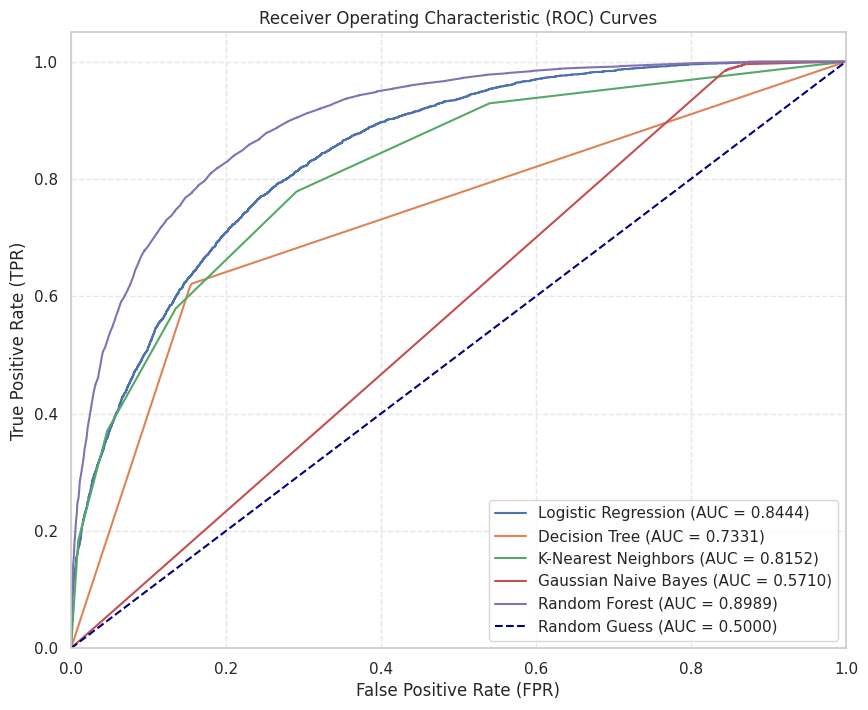

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 8))

# Loop through each model in the models dictionary to plot its ROC curve
for name, model in models.items():
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_processed)[:, 1]
    elif hasattr(model, "decision_function"):
        y_prob = model.decision_function(X_test_processed)
    else:
        y_prob = model.predict(X_test_processed)

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.4f})')

# Plot the diagonal line representing random guessing
plt.plot([0, 1], [0, 1], color='navy', linestyle='--', label='Random Guess (AUC = 0.5000)')

# Add plot aesthetics
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

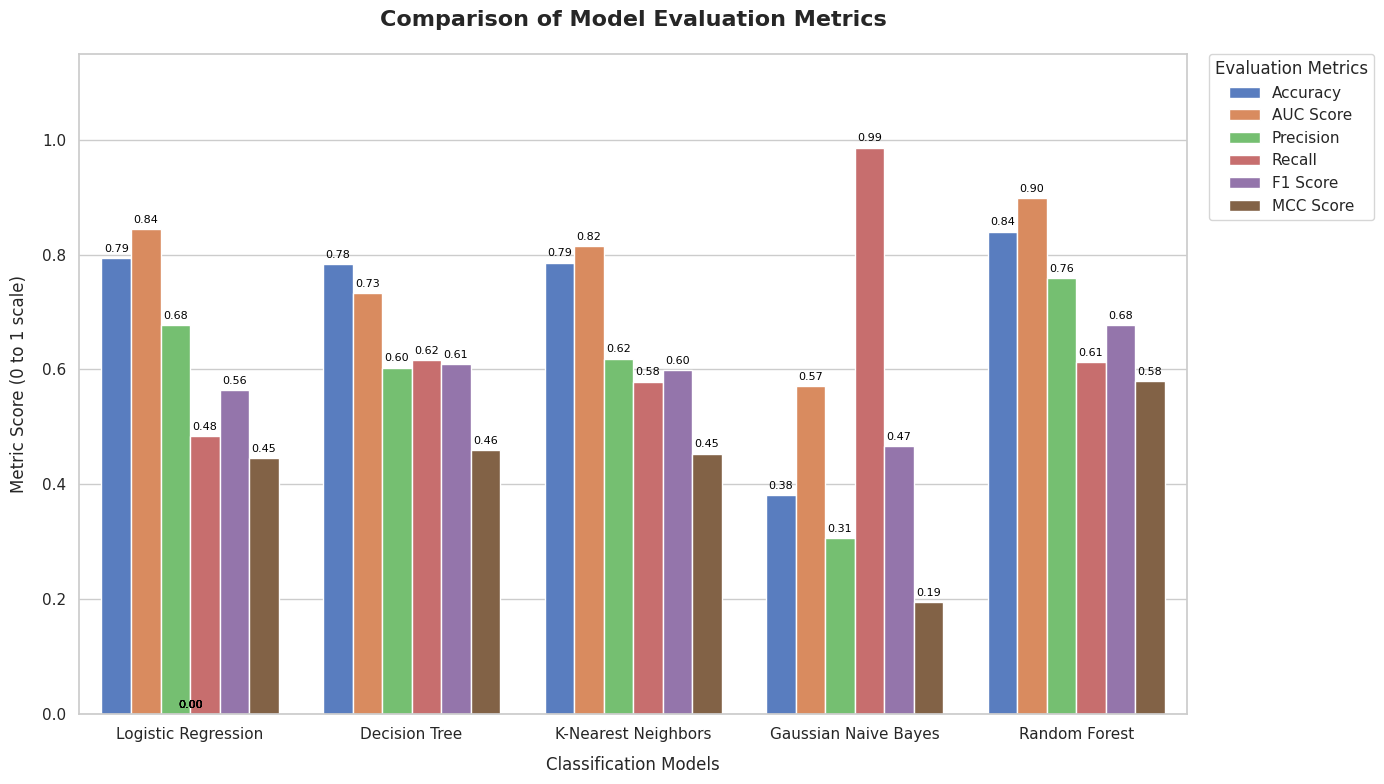

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare the data for plotting by melting the performance DataFrame
df_melted = df_performance.melt(id_vars="Model", var_name="Metric", value_name="Value")

# Create the bar plot
plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

# Create grouped bar chart
ax = sns.barplot(x="Model", y="Value", hue="Metric", data=df_melted, palette="muted")

# Add values on top of the bars for clarity
for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height):
        ax.annotate(f'{height:.2f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=8, color='black', xytext=(0, 3),
                    textcoords='offset points')

# Customize plot aesthetics
plt.title("Comparison of Model Evaluation Metrics", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Classification Models", fontsize=12, labelpad=10)
plt.ylabel("Metric Score (0 to 1 scale)", fontsize=12, labelpad=10)
plt.ylim(0, 1.15)  # Leave room for text labels
plt.legend(title="Evaluation Metrics", bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()
plt.show()

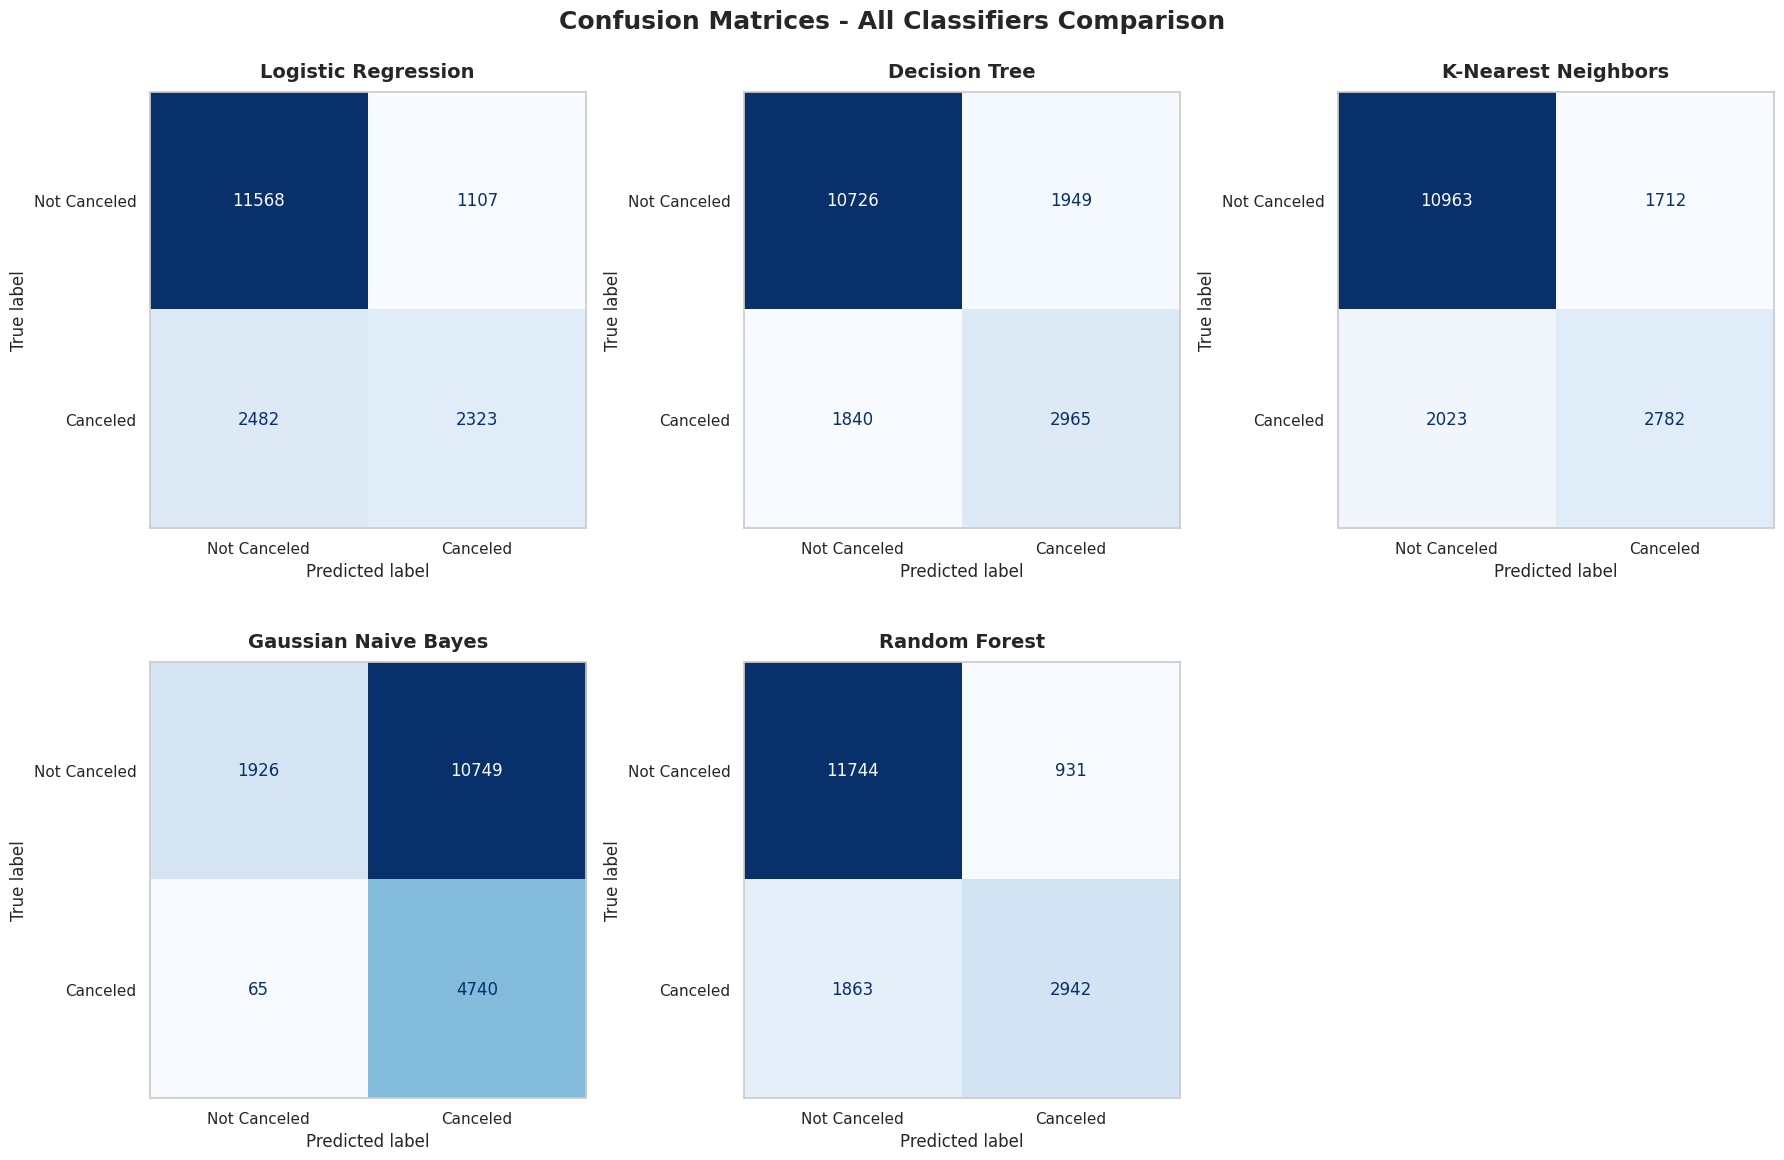

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import math

# Set up the subplot grid (2 rows, 3 columns to fit all 5 models)
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel() # Flatten the 2D grid of axes

# Loop through all trained models and plot their confusion matrices
for idx, (name, model) in enumerate(models.items()):
    # Predict class labels
    y_pred = model.predict(X_test_processed)

    # Calculate confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Display on the corresponding subplot axis
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Canceled", "Canceled"])
    disp.plot(cmap=plt.cm.Blues, values_format='d', ax=axes[idx], colorbar=False)

    axes[idx].set_title(f"{name}", fontsize=14, fontweight='bold', pad=10)
    axes[idx].grid(False)

# Hide the unused 6th subplot axis
axes[5].axis('off')

# Adjust spacing and display the plot grid
plt.suptitle("Confusion Matrices - All Classifiers Comparison", fontsize=18, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()